# Implementasi Particle Swarm Optimization (PSO)
# Marsa Naufal - 04231047
# Tugas PSO: cari tempat dan atur jadwal

## 1. Lihat contoh yang sudah ada

Dua notebook awal berisi contoh mencari nilai terkecil dan rute keliling lima kedai. Data jaraknya ada di `data_janji_jiwa.csv`.

Alurnya sudah benar: coba jawaban → hitung nilainya → simpan yang terbaik → bergerak lagi. Kode awal memakai PySwarms. Di sini kita tulis langkahnya dengan NumPy supaya mudah dilihat.

Yang perlu dibenahi:

- `pos2route` mengubah data partikel saat menghitung nilai. Kalau ada angka nol atau sama, rutenya juga bisa salah.
- Nilai terbaik dihitung ulang terus, padahal bisa disimpan.
- Belum ada perbandingan beberapa seed dan pemeriksaan semua aturan.

Di versi ini, kita urutkan skor dengan `argsort`, salin jawaban terbaik dengan `.copy()`, dan periksa hasilnya. File awal tetap utuh.

Rujukan: [cara kerja operator PySwarms](https://pyswarms.readthedocs.io/en/latest/_modules/pyswarms/backend/operators.html).

### Siapkan alatnya

Kita panggil paket Python dulu. **Seed** itu angka untuk mengulang percobaan acak yang sama. Hasil tambahan masuk ke folder `hasil_pso` di folder kerja notebook.

In [1]:
import sys, platform, time, json
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'font.size': 10})
OUTPUT = Path('hasil_pso')
OUTPUT.mkdir(exist_ok=True)
SEEDS = [11, 22, 33, 44, 55]
HOLDOUT_SEEDS = [101, 202, 303]
DATA_SEED = 20260922
environment = {'python': sys.version, 'platform': platform.platform(),
               **{p: version(p) for p in ['numpy', 'pandas', 'matplotlib', 'ipython', 'nbformat', 'nbclient', 'ipykernel']}}
display(pd.Series(environment, name='Versi aktual').to_frame())
(OUTPUT / 'environment.json').write_text(json.dumps(environment, indent=2))
print('Folder hasil:', OUTPUT.resolve())

,Versi aktual
python,"3.13.15 (v3.13.15:4061bc4c35f, Aug 5 2026, 09..."
platform,macOS-15.7.7-arm64-arm-64bit-Mach-O
numpy,2.5.3
pandas,3.0.5
matplotlib,3.11.2
ipython,9.17.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


Folder hasil: /Users/marsanaufal/Documents/Application/Jupyter/pso_pengembangan/hasil_pso


Tabel di atas menunjukkan versi paket yang dipakai. Seed dibuat tetap; waktu jalan bisa sedikit berubah.

## 2. PSO itu ngapain?

Bayangkan ada banyak teman yang mencari tempat paling bagus. Tiap teman mencoba, ingat tempat terbaiknya, lalu belajar dari teman yang paling berhasil. Teman-teman ini disebut **partikel**.

Rumus geraknya:

$$v_{baru}=w v+c_1r_1(p-x)+c_2r_2(g-x)$$
$$x_{baru}=x+v_{baru}$$

- $x$: posisi sekarang; $v$: arah dan besar langkah.
- $p$: posisi terbaik sendiri; $g$: posisi terbaik semua teman.
- $w$: seberapa kuat meneruskan gerak sebelumnya.
- $c_1$: seberapa kuat ikut pengalaman sendiri; $c_2$: seberapa kuat ikut teman.
- $r_1,r_2$: angka acak 0–1, berbeda untuk tiap partikel dan bagian posisi.

Di kode, langkah dibatasi −0,2 sampai 0,2. Posisi dibatasi 0–1. Kalau keluar batas, posisi ditarik ke tepi dan geraknya pada bagian itu dihentikan.

**Nilai lebih kecil = lebih bagus.** Skor partikel nanti diterjemahkan menjadi tempat atau jadwal oleh fungsi bernama *decoder*.

Kita berhenti setelah `rounds` kali pemeriksaan. Putaran pertama memeriksa posisi awal, jadi 60 putaran berarti 59 kali bergerak. Total jawaban yang diperiksa = jumlah partikel × putaran.

Coba dulu pada fungsi kuadrat dari contoh awal. Jawaban benarnya: posisi (0,25; 0,25), nilai −3,25.

In [2]:
@dataclass(frozen=True)
class Config:
    name: str = 'baseline'
    n_particles: int = 20
    w: float = 0.7
    c1: float = 1.5
    c2: float = 1.5
    rounds: int = 60
    vmax: float = 0.2


def pso(objective, dimensions, cfg, seed):
    """Global-best PSO. objective(X) mengembalikan satu cost tiap baris."""
    assert dimensions > 0 and cfg.n_particles > 0 and cfg.rounds > 0
    rng = np.random.default_rng(seed)
    start = time.perf_counter()
    x = rng.uniform(0, 1, (cfg.n_particles, dimensions))
    v = rng.uniform(-cfg.vmax, cfg.vmax, x.shape)
    pbest = x.copy()
    pbest_cost = np.full(cfg.n_particles, np.inf)
    gbest = None
    gbest_cost = np.inf
    history = []
    for t in range(cfg.rounds):
        # 1. Evaluasi; 2. Perbarui memori terbaik pribadi dan global.
        costs = np.asarray(objective(x), dtype=float)
        assert costs.shape == (cfg.n_particles,) and np.isfinite(costs).all()
        improved = costs < pbest_cost
        pbest[improved] = x[improved].copy()
        pbest_cost[improved] = costs[improved]
        j = int(np.argmin(pbest_cost))
        if pbest_cost[j] < gbest_cost:
            gbest, gbest_cost = pbest[j].copy(), float(pbest_cost[j])
        history.append(gbest_cost)
        if t == cfg.rounds - 1:
            break
        # 3. Pembaruan kecepatan/posisi; 4. Penanganan batas skor.
        r1, r2 = rng.random(x.shape), rng.random(x.shape)
        v = cfg.w*v + cfg.c1*r1*(pbest-x) + cfg.c2*r2*(gbest-x)
        v = np.clip(v, -cfg.vmax, cfg.vmax)
        proposed = x + v
        outside = (proposed < 0) | (proposed > 1)
        x = np.clip(proposed, 0, 1)
        v[outside] = 0
    return {'position': gbest, 'cost': gbest_cost, 'history': np.array(history),
            'evals': cfg.n_particles*cfg.rounds, 'seconds': time.perf_counter()-start}

# Pemeriksaan bermakna terhadap solusi analitis contoh asli.
def quadratic_unit(X):
    a, b = X[:, 0], X[:, 1]
    return 3*a*a - 2*a*b + 3*b*b - a - b - 3

q = pso(quadratic_unit, 2, Config(rounds=100), seed=42)
assert abs(q['cost'] + 3.25) < 1e-6
assert np.all(np.diff(q['history']) <= 1e-12)
print('Uji kuadrat:', q['position'], 'cost =', q['cost'], '; acuan analitis = -3.25')

Uji kuadrat: [0.25000002 0.25000001] cost = -3.2499999999999987 ; acuan analitis = -3.25


Kalau nilainya dekat −3,25, uji dasar berhasil. Catatan nilai terbaik hanya boleh tetap atau turun, karena jawaban lama yang bagus tetap disimpan.

### Coba beberapa pengaturan

Pengaturan awal (*baseline*): 20 partikel, 60 putaran, `w=0.7`, `c1=c2=1.5`.

Kita ubah satu hal setiap kali:

| Yang diubah | Nilai yang dicoba |
|---|---|
| Jumlah partikel | 10, 20, 40 |
| `w` | 0.4, 0.7, 0.9 |
| `c1` dan `c2` | masing-masing 0.5, 1.5, 2.0 |
| Putaran | 30, 60, 120 |

Rentangnya kecil dulu supaya ringan: coba gerak yang lebih lemah/kuat dan waktu pencarian yang lebih pendek/panjang. Pengaturan TSP asli juga ikut dicoba.

Supaya adil, kita bandingkan 10 × 120, 20 × 60, dan 40 × 30. Semuanya **1.200 pemeriksaan**. Semua pengaturan memakai lima seed yang sama.

Pilih rata-rata nilai terkecil. Kalau selisihnya paling banyak 0,1% dari yang terbaik, pilih yang lebih cepat. Lalu cek lagi dengan tiga seed baru. Data kotanya dan rumahnya tetap sama.

In [3]:
BASE = Config()
CONFIGS = [BASE, Config('contoh_asli', 10, 0.9, 0.5, 0.3, 20)]
for field, values in [('n_particles', [10, 40]), ('w', [0.4, 0.9]),
                      ('c1', [0.5, 2.0]), ('c2', [0.5, 2.0]), ('rounds', [30, 120])]:
    for value in values:
        CONFIGS.append(replace(BASE, name=f'{field}_{value}', **{field: value}))
CONFIGS += [replace(BASE, name='anggaran_N10', n_particles=10, rounds=120),
            replace(BASE, name='anggaran_N40', n_particles=40, rounds=30)]
CONFIG_MAP = {c.name: c for c in CONFIGS}
config_table = pd.DataFrame([asdict(c) for c in CONFIGS])
config_table['evaluasi_per_run'] = config_table.n_particles*config_table.rounds
display(config_table)
print(f'{len(CONFIGS)} konfigurasi × {len(SEEDS)} seed = {len(CONFIGS)*len(SEEDS)} run per kasus.')
config_table.to_csv(OUTPUT/'konfigurasi.csv', index=False)


def run_experiment(objective, dimensions, decode, valid, configs, seeds, label):
    rows, runs = [], {}
    for seed in seeds:
        order = np.random.default_rng(seed + 9000).permutation(len(configs))
        for j in order:
            cfg = configs[j]
            result = pso(objective, dimensions, cfg, seed)
            solution = decode(result['position'])
            feasible = bool(valid(solution))
            # Evaluasi ulang untuk pemeriksaan, di luar anggaran pencarian.
            assert np.isclose(result['cost'], objective(result['position'][None, :])[0])
            assert feasible and np.all(np.diff(result['history']) <= 1e-10)
            assert result['evals'] == cfg.n_particles * cfg.rounds
            rows.append({'case': label, 'config': cfg.name, 'seed': seed,
                         'cost': result['cost'], 'feasible': feasible,
                         'seconds': result['seconds'], 'evals': result['evals']})
            runs[(cfg.name, seed)] = result
    raw = pd.DataFrame(rows)
    summary = raw.groupby('config', sort=False).agg(
        best=('cost', 'min'), mean=('cost', 'mean'), std=('cost', 'std'),
        feasible_rate=('feasible', 'mean'), seconds_mean=('seconds', 'mean'),
        seconds_std=('seconds', 'std'), evaluations=('evals', 'first'), runs=('seed', 'size'))
    summary = summary.join(pd.DataFrame([asdict(c) for c in configs]).set_index('name'))
    return raw, summary.sort_values(['mean', 'seconds_mean']), runs


def choose_config(summary):
    best_mean = summary['mean'].min()
    acceptable = summary[summary['mean'] <= best_mean + abs(best_mean)*0.001]
    return acceptable.sort_values(['seconds_mean', 'mean']).index[0]


def plot_tuning(summary, runs, selected, label, unit):
    names = list(dict.fromkeys(['contoh_asli', 'baseline', 'anggaran_N10', 'anggaran_N40', selected]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for name in names:
        cfg = CONFIG_MAP[name]
        trajectories = np.array([runs[(name, seed)]['history'] for seed in SEEDS])
        avg, sd = trajectories.mean(0), trajectories.std(0, ddof=1)
        rounds = np.arange(1, cfg.rounds+1)
        for ax, xaxis in zip(axes[:2], [rounds, rounds*cfg.n_particles]):
            ax.plot(xaxis, avg, label=name)
            ax.fill_between(xaxis, avg-sd, avg+sd, alpha=0.12)
    axes[0].set(xlabel='Putaran evaluasi', ylabel=unit, title='Konvergensi: mean ± SD')
    axes[1].set(xlabel='Evaluasi solusi kumulatif', ylabel=unit, title='Konvergensi menurut anggaran')
    axes[1].legend(fontsize=7)
    budgets = sorted(summary.evaluations.unique())
    colors = dict(zip(budgets, plt.cm.viridis(np.linspace(0.1, 0.9, len(budgets)))))
    seen = set()
    for name, row in summary.iterrows():
        budget = int(row.evaluations)
        label_budget = f'{budget} evaluasi' if budget not in seen else None
        seen.add(budget)
        axes[2].errorbar(row.seconds_mean, row['mean'], yerr=row['std'], fmt='o', capsize=2,
                        color=colors[budget], alpha=0.75, label=label_budget)
        if name in ['baseline', selected]:
            offset = (8, 14) if name == selected else (8, -20)
            axes[2].annotate(name, (row.seconds_mean, row['mean']), xytext=offset,
                            textcoords='offset points', fontsize=8, arrowprops={'arrowstyle': '-'})
    axes[2].legend(fontsize=7)
    axes[2].set(xlabel='Rata-rata detik per run', ylabel=unit, title='Kualitas vs waktu (SD antar-seed)')
    fig.suptitle(label)
    fig.tight_layout()
    fig.savefig(OUTPUT/f'{label}_tuning.png', dpi=150)
    plt.show()


def interpret_tuning(summary, selected, label, unit):
    row, baseline = summary.loc[selected], summary.loc['baseline']
    improvement = 100*(baseline['mean']-row['mean'])/baseline['mean']
    display(Markdown(f'**Hasil {label}:** pilih **{selected}**. '
        f'rata-rata {row["mean"]:.4f} {unit}, SD {row["std"]:.4f}, '
        f'terbaik {row.best:.4f}; {row.seconds_mean:.4f} detik/run dan '
        f'{int(row.evaluations):,} evaluasi/run. Dibanding pengaturan awal, '
        f'nilainya turun {improvement:.2f}%. Semua hasil memenuhi aturan: '
        f'{summary.feasible_rate.eq(1).all()}. Area berwarna menunjukkan SD antarpercobaan.'))
    equal = summary[summary.evaluations == BASE.n_particles*BASE.rounds]
    display(Markdown('**Biar adil:** tabel ini sama-sama memakai 1.200 pemeriksaan. '
        'Waktunya tetap bisa berbeda.'))
    display(equal[['mean', 'std', 'seconds_mean', 'evaluations']])
    display(Markdown('**Lihat selisihnya:** delta positif berarti lebih buruk dari pengaturan awal. '
        'Jumlah partikel dan putaran juga mengubah banyaknya pemeriksaan.'))
    effects = summary[['mean', 'std', 'evaluations']].copy()
    effects['delta_mean_vs_baseline'] = effects['mean'] - baseline['mean']
    effects['rasio_evaluasi'] = effects.evaluations / baseline.evaluations
    display(effects)
    for field, variants in [('n_particles', ['n_particles_10', 'baseline', 'n_particles_40']),
                            ('w', ['w_0.4', 'baseline', 'w_0.9']),
                            ('c1', ['c1_0.5', 'baseline', 'c1_2.0']),
                            ('c2', ['c2_0.5', 'baseline', 'c2_2.0']),
                            ('rounds', ['rounds_30', 'baseline', 'rounds_120'])]:
        observations = '; '.join(f'{summary.loc[n, field]:g} → {summary.loc[n, "mean"]:.4f}' for n in variants)
        budget_note = 'Jumlah pemeriksaannya berbeda.' if field in ['n_particles', 'rounds'] else 'Sama-sama 1.200 pemeriksaan.'
        display(Markdown(f'- **{field}:** rata-rata nilai {observations} ({unit}). {budget_note} '
                         'Ini hasil dari lima seed.'))


def save_runs(raw, summary, runs, label):
    raw.to_csv(OUTPUT/f'{label}_runs.csv', index=False)
    summary.to_csv(OUTPUT/f'{label}_ringkasan.csv')
    history = []
    for (name, seed), result in runs.items():
        n = int(raw.loc[(raw.config == name) & (raw.seed == seed), 'evals'].iloc[0] / len(result['history']))
        history.extend({'config': name, 'seed': seed, 'round': i+1,
                        'evaluations': (i+1)*n, 'best_cost': cost}
                       for i, cost in enumerate(result['history']))
    pd.DataFrame(history).to_csv(OUTPUT/f'{label}_konvergensi.csv', index=False)

,name,n_particles,w,c1,c2,rounds,vmax,evaluasi_per_run
0,baseline,20,0.7,1.5,1.5,60,0.2,1200
1,contoh_asli,10,0.9,0.5,0.3,20,0.2,200
2,n_particles_10,10,0.7,1.5,1.5,60,0.2,600
3,n_particles_40,40,0.7,1.5,1.5,60,0.2,2400
4,w_0.4,20,0.4,1.5,1.5,60,0.2,1200
5,w_0.9,20,0.9,1.5,1.5,60,0.2,1200
6,c1_0.5,20,0.7,0.5,1.5,60,0.2,1200
7,c1_2.0,20,0.7,2.0,1.5,60,0.2,1200
8,c2_0.5,20,0.7,1.5,0.5,60,0.2,1200
9,c2_2.0,20,0.7,1.5,2.0,60,0.2,1200


14 konfigurasi × 5 seed = 70 run per kasus.


Ada **14 pengaturan × 5 seed = 70 percobaan per kasus**. `mean` artinya rata-rata; `std` atau SD menunjukkan seberapa berbeda hasil antarpercobaan. SD kecil berarti hasilnya lebih konsisten.

## 3. Kota: fasilitasnya ditaruh di mana?

Kita punya kota buatan 10 × 10 km, 100 kelompok warga, dan 25 calon tempat. Kita pilih **4 tempat berbeda** supaya warga lebih dekat ke fasilitas.

Setiap kelompok punya jumlah warga yang berbeda. Kelompok yang lebih ramai diberi bobot lebih besar.

$$\text{nilai} = \frac{\sum(\text{jumlah warga}\times\text{jarak ke fasilitas terdekat})}{\text{total warga}}$$

Jarak dihitung lurus. Jalan, kapasitas fasilitas, dan biaya bangun belum dihitung. Batasnya empat fasilitas; kita pakai keempatnya karena menambah fasilitas tidak memperburuk jarak dalam model ini.

Satu partikel punya 25 skor. **Ambil empat skor terkecil**, lalu pakai tempatnya. Kalau skornya sama, urutkan menurut nomor tempat. Jadi tidak ada tempat dobel.

PSO cocok dicoba karena cukup menghitung bagus-jeleknya jawaban, tanpa perlu turunan rumus. Kita mulai dari empat sudut kota sebagai pembanding.

In [4]:
def make_city(seed=DATA_SEED):
    rng = np.random.default_rng(seed)
    centers = np.array([[2, 2], [7, 3], [5, 8]])
    group = rng.choice(3, size=100, p=[0.4, 0.35, 0.25])
    demand = np.clip(centers[group] + rng.normal(0, 1.1, (100, 2)), 0, 10)
    population = rng.integers(50, 501, size=100)
    grid = np.linspace(1, 9, 5)
    candidates = np.array([(x, y) for y in grid for x in grid])
    distances = np.linalg.norm(demand[:, None, :] - candidates[None, :, :], axis=2)
    return demand, population, candidates, distances

DEMAND, POPULATION, CANDIDATES, DISTANCE = make_city()
K = 4

def decode_city(x):
    return np.sort(np.argsort(x, kind='stable')[:K])

def city_valid(selected):
    s = np.asarray(selected)
    return s.shape == (K,) and len(np.unique(s)) == K and np.issubdtype(s.dtype, np.integer) and np.all((s >= 0) & (s < len(CANDIDATES)))

def city_cost_selected(selected):
    return float(np.average(DISTANCE[:, selected].min(axis=1), weights=POPULATION))

def city_objective(X):
    selected = np.argsort(X, axis=1, kind='stable')[:, :K]
    nearest = DISTANCE[:, selected].min(axis=2)  # (100 permintaan, N partikel)
    return np.average(nearest, axis=0, weights=POPULATION)

CITY_BEFORE = np.array([0, 4, 20, 24])
assert city_valid(CITY_BEFORE)
probe = np.zeros((2, 25))
unchanged = probe.copy()
assert city_valid(decode_city(probe[0]))
city_objective(probe)
assert np.array_equal(probe, unchanged)
pd.DataFrame({'x_km': DEMAND[:,0], 'y_km': DEMAND[:,1], 'penduduk': POPULATION}).to_csv(OUTPUT/'kota_penduduk_sintetis.csv', index=False)
pd.DataFrame(CANDIDATES, columns=['x_km', 'y_km']).to_csv(OUTPUT/'kota_kandidat_sintetis.csv', index=False)
print('Penduduk total:', POPULATION.sum(), '; baseline layanan:', city_cost_selected(CITY_BEFORE), 'km')
display(pd.DataFrame({'kandidat': CITY_BEFORE, 'x_km': CANDIDATES[CITY_BEFORE,0], 'y_km': CANDIDATES[CITY_BEFORE,1]}))

Penduduk total: 25150 ; baseline layanan: 2.705270962107984 km


,kandidat,x_km,y_km
0,0,1.0,1.0
1,4,9.0,1.0
2,20,1.0,9.0
3,24,9.0,9.0


Angka di atas adalah rata-rata jarak yang dirasakan warga. Makin kecil, makin dekat. Tapi rata-rata kecil belum tentu berarti semua warga sudah dekat.

### Coba PSO untuk kota

Jalankan semua pengaturan pada data yang sama. Tabel mencatat nilai terbaik, rata-rata, SD, waktu, jumlah pemeriksaan, dan apakah aturannya dipenuhi.

,best,mean,std,feasible_rate,seconds_mean,seconds_std,evaluations,runs,n_particles,w,c1,c2,rounds,vmax
config,,,,,,,,,,,,,,
c2_0.5,1.272588,1.370464,0.071222,1.0,0.003033,0.000162,1200,5,20,0.7,1.5,0.5,60,0.2
w_0.4,1.322065,1.383994,0.062738,1.0,0.002861,0.000038,1200,5,20,0.4,1.5,1.5,60,0.2
w_0.9,1.322065,1.385421,0.058236,1.0,0.002958,0.000035,1200,5,20,0.9,1.5,1.5,60,0.2
anggaran_N40,1.348428,1.393911,0.091393,1.0,0.002193,0.000083,1200,5,40,0.7,1.5,1.5,30,0.2
n_particles_40,1.348428,1.393911,0.091393,1.0,0.004319,0.000194,2400,5,40,0.7,1.5,1.5,60,0.2
baseline,1.272588,1.408367,0.101454,1.0,0.003047,0.000267,1200,5,20,0.7,1.5,1.5,60,0.2
rounds_120,1.272588,1.408367,0.101454,1.0,0.005949,0.000219,2400,5,20,0.7,1.5,1.5,120,0.2
c2_2.0,1.322065,1.432420,0.080549,1.0,0.002993,0.000142,1200,5,20,0.7,1.5,2.0,60,0.2
c1_2.0,1.363516,1.432784,0.070609,1.0,0.002982,0.000145,1200,5,20,0.7,2.0,1.5,60,0.2


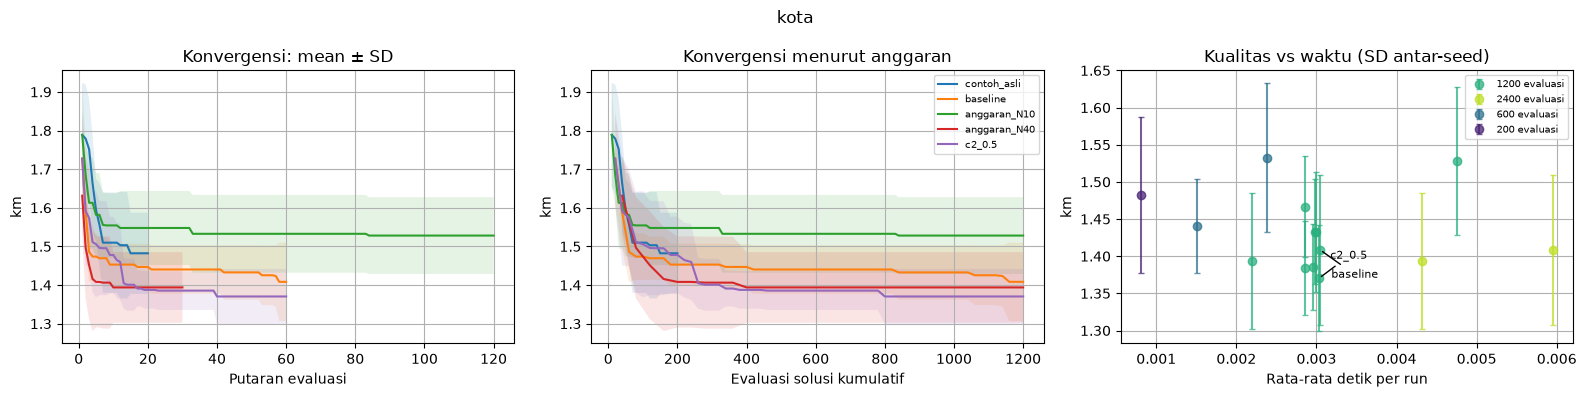

**Hasil kota:** pilih **c2_0.5**: rata-rata 1.3705 km, SD 0.0712, terbaik 1.2726; 0.0030 detik/run dan 1,200 evaluasi/run. Dibanding pengaturan awal, nilainya turun 2.69%. Semua hasil memenuhi aturan: True. Area berwarna menunjukkan SD antarpercobaan.

**Biar adil:** tabel ini sama-sama memakai 1.200 pemeriksaan. Waktunya tetap bisa berbeda.

,mean,std,seconds_mean,evaluations
config,,,,
c2_0.5,1.370464,0.071222,0.003033,1200
w_0.4,1.383994,0.062738,0.002861,1200
w_0.9,1.385421,0.058236,0.002958,1200
anggaran_N40,1.393911,0.091393,0.002193,1200
baseline,1.408367,0.101454,0.003047,1200
c2_2.0,1.432420,0.080549,0.002993,1200
c1_2.0,1.432784,0.070609,0.002982,1200
c1_0.5,1.466466,0.067888,0.002858,1200
anggaran_N10,1.528131,0.099406,0.004748,1200


**Lihat selisihnya:** delta positif berarti lebih buruk dari pengaturan awal. Jumlah partikel dan putaran juga mengubah banyaknya pemeriksaan.

,mean,std,evaluations,delta_mean_vs_baseline,rasio_evaluasi
config,,,,,
c2_0.5,1.370464,0.071222,1200,-0.037904,1.000000
w_0.4,1.383994,0.062738,1200,-0.024373,1.000000
w_0.9,1.385421,0.058236,1200,-0.022946,1.000000
anggaran_N40,1.393911,0.091393,1200,-0.014456,1.000000
n_particles_40,1.393911,0.091393,2400,-0.014456,2.000000
baseline,1.408367,0.101454,1200,0.000000,1.000000
rounds_120,1.408367,0.101454,2400,0.000000,2.000000
c2_2.0,1.432420,0.080549,1200,0.024052,1.000000
c1_2.0,1.432784,0.070609,1200,0.024417,1.000000


- **n_particles:** rata-rata nilai 10 → 1.5327; 20 → 1.4084; 40 → 1.3939 (km). Jumlah pemeriksaannya berbeda. Ini hasil dari lima seed.

- **w:** rata-rata nilai 0.4 → 1.3840; 0.7 → 1.4084; 0.9 → 1.3854 (km). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **c1:** rata-rata nilai 0.5 → 1.4665; 1.5 → 1.4084; 2 → 1.4328 (km). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **c2:** rata-rata nilai 0.5 → 1.3705; 1.5 → 1.4084; 2 → 1.4324 (km). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **rounds:** rata-rata nilai 30 → 1.4403; 60 → 1.4084; 120 → 1.4084 (km). Jumlah pemeriksaannya berbeda. Ini hasil dari lima seed.

In [5]:
city_raw, city_summary, city_runs = run_experiment(
    city_objective, 25, decode_city, city_valid, CONFIGS, SEEDS, 'kota')
city_choice = choose_config(city_summary)
save_runs(city_raw, city_summary, city_runs, 'kota')
display(city_summary)
plot_tuning(city_summary, city_runs, city_choice, 'kota', 'km')
interpret_tuning(city_summary, city_choice, 'kota', 'km')

Lihat juga grafik **jumlah pemeriksaan**, bukan cuma putaran. Satu putaran berisi 40 partikel lebih banyak kerja daripada 10 partikel. Grafik mendatar berarti belum menemukan jawaban lebih baik, belum tentu sudah paling baik.

### Lihat petanya

Cek pengaturan terpilih dengan tiga seed baru. Untuk peta, ambil hasil yang di tengah dari tiga percobaan itu. Sebelum dan sesudah sama-sama memakai empat fasilitas.

,best,mean,std,feasible_rate,seconds_mean,evaluations
config,,,,,,
c2_0.5,1.272588,1.333207,0.052497,1.0,0.002967,1200
baseline,1.272588,1.356173,0.072461,1.0,0.003063,1200


,solusi,jumlah_fasilitas,rata_rata_km,jarak_maks_km,layak
0,Sebelum (sudut),4,2.705271,4.921601,True
1,Sesudah (PSO),4,1.363516,3.178930,True


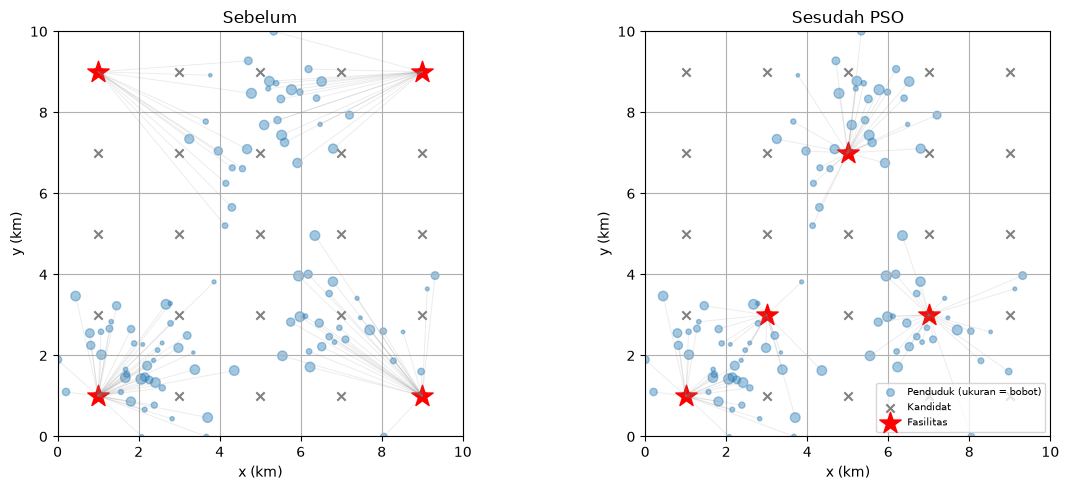

**Hasil kota:** seed 101 memilih tempat **[0, 6, 8, 17]**, menurunkan rata-rata jarak sebesar **49.60%** terhadap empat sudut. Garis pada peta menghubungkan warga ke fasilitas terdekat. Pembandingnya adalah empat tempat di sudut kota.

In [6]:
city_check_configs = [BASE] if city_choice == 'baseline' else [BASE, CONFIG_MAP[city_choice]]
city_test_raw, city_test_summary, city_test_runs = run_experiment(
    city_objective, 25, decode_city, city_valid, city_check_configs, HOLDOUT_SEEDS, 'kota_validasi')
save_runs(city_test_raw, city_test_summary, city_test_runs, 'kota_validasi')
display(city_test_summary[['best', 'mean', 'std', 'feasible_rate', 'seconds_mean', 'evaluations']])
city_median_seed = int(city_test_raw[city_test_raw.config == city_choice].sort_values('cost').iloc[1].seed)
CITY_AFTER = decode_city(city_test_runs[(city_choice, city_median_seed)]['position'])
assert city_valid(CITY_AFTER)
city_comparison = pd.DataFrame([
    {'solusi': name, 'jumlah_fasilitas': len(s), 'rata_rata_km': city_cost_selected(s),
     'jarak_maks_km': DISTANCE[:, s].min(axis=1).max(), 'layak': city_valid(s)}
    for name, s in [('Sebelum (sudut)', CITY_BEFORE), ('Sesudah (PSO)', CITY_AFTER)]])
display(city_comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, selected, title in zip(axes, [CITY_BEFORE, CITY_AFTER], ['Sebelum', 'Sesudah PSO']):
    ax.scatter(DEMAND[:,0], DEMAND[:,1], s=POPULATION/9, alpha=0.4, label='Penduduk (ukuran = bobot)')
    ax.scatter(CANDIDATES[:,0], CANDIDATES[:,1], marker='x', color='gray', label='Kandidat')
    ax.scatter(CANDIDATES[selected,0], CANDIDATES[selected,1], marker='*', s=260, color='red', label='Fasilitas')
    assignments = selected[np.argmin(DISTANCE[:,selected], axis=1)]
    for point, target in zip(DEMAND, CANDIDATES[assignments]):
        ax.plot([point[0], target[0]], [point[1], target[1]], color='gray', alpha=0.15, lw=0.7)
    ax.set(title=title, xlabel='x (km)', ylabel='y (km)', xlim=(0,10), ylim=(0,10), aspect='equal')
axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUTPUT/'kota_peta.png', dpi=150); plt.show()
city_gain = 100*(1-city_cost_selected(CITY_AFTER)/city_cost_selected(CITY_BEFORE))
display(Markdown(f'**Hasil kota:** seed {city_median_seed} memilih tempat '
    f'**{CITY_AFTER.tolist()}**, menurunkan rata-rata jarak sebesar **{city_gain:.2f}%** terhadap empat sudut. '
    'Garis pada peta menghubungkan warga ke fasilitas terdekat. '
    'Pembandingnya adalah empat tempat di sudut kota.'))
city_comparison.to_csv(OUTPUT/'kota_sebelum_sesudah.csv', index=False)

Titik merah menunjukkan fasilitas yang dipilih. Ini baru latihan pada satu kota buatan; jalan, lahan, kapasitas, dan pemerataan layanan belum masuk hitungan.

## 4. Rumah: alatnya nyala jam berapa?

Ada enam alat. Kita geser jam nyalanya supaya biaya lebih murah.

Aturannya:

- Tiap alat menyala sekali, selama durasinya, tanpa putus.
- Alat hanya boleh menyala dalam jam yang diizinkan dan harus selesai hari itu.
- Total daya rumah paling tinggi **4 kW**, termasuk pemakaian dasar.

Contoh: boleh dipakai jam 6–12, butuh 2 jam → boleh mulai jam 6 sampai 10.

$$\text{biaya} = \sum_{jam=0}^{23}(\text{daya total}\times 1\text{ jam}\times\text{tarif})$$

Satu hari dibagi 24 bagian, masing-masing satu jam. Tarif dan pemakaian listriknya **buatan**, bukan tarif PLN. Baterai dan panel surya belum dipakai.

Kita cek jadwal awal dulu. Jadwal ini harus memenuhi aturan yang sama dengan hasil PSO.

In [7]:
DEVICES = pd.DataFrame([
    ['Mesin cuci',         0.6, 2,  6, 16,  8],
    ['Pengering',          1.8, 2, 10, 22, 18],
    ['Pencuci piring',     1.2, 2, 12, 24, 20],
    ['Pemanas air',        1.5, 2,  5, 23, 16],
    ['Pengisi kendaraan',  2.0, 4,  0, 12,  6],
    ['Pompa air',          0.5, 3,  6, 22, 16],
], columns=['perangkat', 'daya_kw', 'durasi_jam', 'earliest', 'deadline', 'mulai_awal'])
HOURS = np.arange(24)
TARIFF = np.array([900]*6 + [1500]*10 + [2600]*6 + [1100]*2, dtype=float)
BASE_LOAD = np.array([0.35]*6 + [0.6]*3 + [0.45]*7 + [0.7]*6 + [0.4]*2)
POWER_LIMIT = 4.0
POWER = DEVICES.daya_kw.to_numpy()
DURATION = DEVICES.durasi_jam.to_numpy(dtype=int)
EARLIEST = DEVICES.earliest.to_numpy(dtype=int)
DEADLINE = DEVICES.deadline.to_numpy(dtype=int)
HOME_BEFORE = DEVICES.mulai_awal.to_numpy(dtype=int)
M = len(DEVICES)


def home_profile(starts):
    active = (HOURS[None, :] >= np.asarray(starts)[:, None]) & (HOURS[None, :] < (np.asarray(starts)+DURATION)[:, None])
    return BASE_LOAD + (POWER[:,None]*active).sum(axis=0)


def home_valid(starts):
    s = np.asarray(starts)
    return (s.shape == (M,) and np.issubdtype(s.dtype, np.integer)
            and np.all(s >= EARLIEST) and np.all(s + DURATION <= DEADLINE)
            and np.all(home_profile(s) <= POWER_LIMIT + 1e-9))


def home_cost_starts(starts):
    return float(np.dot(home_profile(starts), TARIFF))  # kW × 1 jam × Rp/kWh

assert home_valid(HOME_BEFORE), 'Baseline awal harus diperbaiki agar memenuhi semua batasan.'
display(DEVICES)
display(pd.DataFrame({'jam': HOURS, 'tarif_rp_kwh': TARIFF, 'beban_dasar_kw': BASE_LOAD}))
print('Biaya awal:', home_cost_starts(HOME_BEFORE), 'Rp/hari; puncak:', home_profile(HOME_BEFORE).max(), 'kW')
DEVICES.to_csv(OUTPUT/'rumah_perangkat_sintetis.csv', index=False)
pd.DataFrame({'jam': HOURS, 'tarif_rp_kwh': TARIFF, 'beban_dasar_kw': BASE_LOAD}).to_csv(OUTPUT/'rumah_tarif_beban_sintetis.csv', index=False)

,perangkat,daya_kw,durasi_jam,earliest,deadline,mulai_awal
0,Mesin cuci,0.6,2,6,16,8
1,Pengering,1.8,2,10,22,18
2,Pencuci piring,1.2,2,12,24,20
3,Pemanas air,1.5,2,5,23,16
4,Pengisi kendaraan,2.0,4,0,12,6
5,Pompa air,0.5,3,6,22,16


,jam,tarif_rp_kwh,beban_dasar_kw
0,0,900.0,0.35
1,1,900.0,0.35
2,2,900.0,0.35
3,3,900.0,0.35
4,4,900.0,0.35
5,5,900.0,0.35
6,6,1500.0,0.60
7,7,1500.0,0.60
8,8,1500.0,0.60
9,9,1500.0,0.45


Biaya awal: 62215.0 Rp/hari; puncak: 3.2 kW


Jadwal awal sudah dicek: jamnya boleh, durasinya cukup, dan dayanya tidak berlebihan. Mesin cuci dan pengering masih dianggap terpisah; belum ada aturan pengering harus menunggu cucian.

### Ubah skor menjadi jadwal

Satu partikel punya 12 angka: enam untuk jam mulai yang diinginkan, enam untuk urutan alat yang dijadwalkan.

Jam mulai dibulatkan ke jam yang boleh. Alat dijadwalkan satu per satu. Kalau dayanya terlalu besar, coba jam lain yang paling dekat. Kalau tetap buntu, pakai kembali **seluruh jadwal awal yang sudah aman**.

Jadi hasil tetap memenuhi aturan. Cara ini sederhana, tetapi bisa membuat banyak partikel menghasilkan jadwal yang sama. PSO mencari biaya murah; decoder hanya membantu menjaga aturannya.

Kita cek juga 500 partikel acak dan dua contoh di batas 0 dan 1.

In [8]:
ALLOWED = [np.arange(a, b-d+1, dtype=int) for a,b,d in zip(EARLIEST, DEADLINE, DURATION)]


def decode_home(x, details=False):
    x = np.asarray(x)
    preferred = EARLIEST + np.floor(np.clip(x[:M], 0, 1)*(DEADLINE-DURATION-EARLIEST) + 0.5).astype(int)
    order = np.argsort(x[M:], kind='stable')
    load = BASE_LOAD.copy()
    starts = np.empty(M, dtype=int)
    fallback = False
    for j in order:
        candidates = ALLOWED[j]
        # lexsort: kunci terakhir primer (jarak), kemudian jam lebih awal.
        candidate_order = np.lexsort((candidates, np.abs(candidates-preferred[j])))
        placed = False
        for s in candidates[candidate_order]:
            stop = s + DURATION[j]
            if np.all(load[s:stop] + POWER[j] <= POWER_LIMIT + 1e-9):
                starts[j] = s
                load[s:stop] += POWER[j]
                placed = True
                break
        if not placed:
            starts = HOME_BEFORE.copy()
            fallback = True
            break
    if details:
        return starts, fallback, int(np.sum(starts != preferred))
    return starts


def home_objective(X):
    return np.array([home_cost_starts(decode_home(x)) for x in X])

rng_diagnostic = np.random.default_rng(987)
home_probes = np.vstack([np.zeros(2*M), np.ones(2*M), rng_diagnostic.random((500, 2*M))])
probes_copy = home_probes.copy()
decoded = [decode_home(x, details=True) for x in home_probes]
assert all(home_valid(s) for s, _, _ in decoded)
assert np.array_equal(home_probes, probes_copy)
assert np.allclose([home_profile(s).sum() for s, _, _ in decoded], home_profile(HOME_BEFORE).sum())
random_decoded = decoded[2:]
print('Uji 2 titik batas + 500 partikel acak: semua layak dan energi tetap.')
print('Fallback pada 500 partikel acak:', np.mean([f for _,f,_ in random_decoded]))
print('Rata-rata perangkat bergeser dari preferensi:', np.mean([n for _,_,n in random_decoded]))

Uji 2 titik batas + 500 partikel acak: semua layak dan energi tetap.
Fallback pada 500 partikel acak: 0.0
Rata-rata perangkat bergeser dari preferensi: 0.28


Semua contoh uji harus punya jadwal yang boleh dan jumlah energi yang sama. `Fallback` berarti kembali ke jadwal awal karena susunan yang dicoba menemui jalan buntu.

### Coba PSO untuk rumah

Pakai pengaturan dan seed yang sama seperti kasus kota. Biaya baru dihitung setelah jadwal dirapikan agar memenuhi aturan.

,best,mean,std,feasible_rate,seconds_mean,seconds_std,evaluations,runs,n_particles,w,c1,c2,rounds,vmax
config,,,,,,,,,,,,,,
rounds_30,44005.0,44569.0,515.441558,1.0,0.024942,0.001341,600,5,20,0.7,1.5,1.5,30,0.2
w_0.9,44005.0,44569.0,515.441558,1.0,0.047850,0.000513,1200,5,20,0.9,1.5,1.5,60,0.2
baseline,44005.0,44569.0,515.441558,1.0,0.048656,0.001128,1200,5,20,0.7,1.5,1.5,60,0.2
rounds_120,44005.0,44569.0,515.441558,1.0,0.096228,0.001830,2400,5,20,0.7,1.5,1.5,120,0.2
contoh_asli,44005.0,44737.0,774.674125,1.0,0.009251,0.002121,200,5,10,0.9,0.5,0.3,20,0.2
n_particles_10,44005.0,44737.0,774.674125,1.0,0.025528,0.001790,600,5,10,0.7,1.5,1.5,60,0.2
anggaran_N10,44005.0,44737.0,774.674125,1.0,0.049441,0.000797,1200,5,10,0.7,1.5,1.5,120,0.2
c1_2.0,44005.0,44749.0,778.382939,1.0,0.047863,0.000351,1200,5,20,0.7,2.0,1.5,60,0.2
c2_2.0,44005.0,44749.0,778.382939,1.0,0.066326,0.039798,1200,5,20,0.7,1.5,2.0,60,0.2


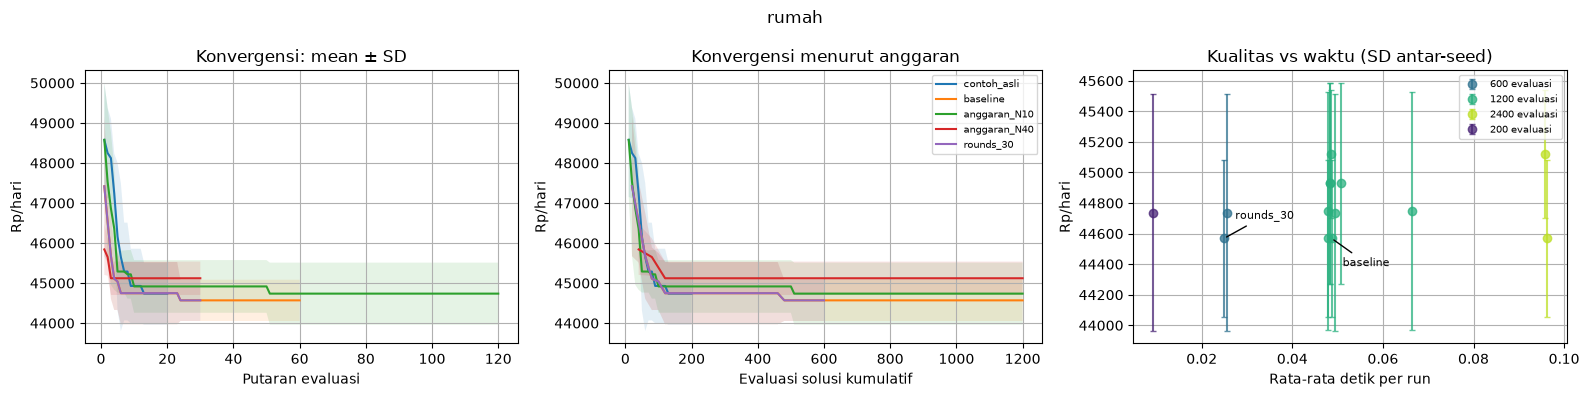

**Hasil rumah:** pilih **rounds_30**: rata-rata 44569.0000 Rp/hari, SD 515.4416, terbaik 44005.0000; 0.0249 detik/run dan 600 evaluasi/run. Dibanding pengaturan awal, nilainya turun 0.00%. Semua hasil memenuhi aturan: True. Area berwarna menunjukkan SD antarpercobaan.

**Biar adil:** tabel ini sama-sama memakai 1.200 pemeriksaan. Waktunya tetap bisa berbeda.

,mean,std,seconds_mean,evaluations
config,,,,
w_0.9,44569.0,515.441558,0.047850,1200
baseline,44569.0,515.441558,0.048656,1200
anggaran_N10,44737.0,774.674125,0.049441,1200
c1_2.0,44749.0,778.382939,0.047863,1200
c2_2.0,44749.0,778.382939,0.066326,1200
w_0.4,44929.0,658.088140,0.048264,1200
c2_0.5,44929.0,658.088140,0.048364,1200
c1_0.5,44929.0,658.088140,0.050679,1200
anggaran_N40,45121.0,416.989208,0.048546,1200


**Lihat selisihnya:** delta positif berarti lebih buruk dari pengaturan awal. Jumlah partikel dan putaran juga mengubah banyaknya pemeriksaan.

,mean,std,evaluations,delta_mean_vs_baseline,rasio_evaluasi
config,,,,,
rounds_30,44569.0,515.441558,600,0.0,0.500000
w_0.9,44569.0,515.441558,1200,0.0,1.000000
baseline,44569.0,515.441558,1200,0.0,1.000000
rounds_120,44569.0,515.441558,2400,0.0,2.000000
contoh_asli,44737.0,774.674125,200,168.0,0.166667
n_particles_10,44737.0,774.674125,600,168.0,0.500000
anggaran_N10,44737.0,774.674125,1200,168.0,1.000000
c1_2.0,44749.0,778.382939,1200,180.0,1.000000
c2_2.0,44749.0,778.382939,1200,180.0,1.000000


- **n_particles:** rata-rata nilai 10 → 44737.0000; 20 → 44569.0000; 40 → 45121.0000 (Rp/hari). Jumlah pemeriksaannya berbeda. Ini hasil dari lima seed.

- **w:** rata-rata nilai 0.4 → 44929.0000; 0.7 → 44569.0000; 0.9 → 44569.0000 (Rp/hari). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **c1:** rata-rata nilai 0.5 → 44929.0000; 1.5 → 44569.0000; 2 → 44749.0000 (Rp/hari). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **c2:** rata-rata nilai 0.5 → 44929.0000; 1.5 → 44569.0000; 2 → 44749.0000 (Rp/hari). Sama-sama 1.200 pemeriksaan. Ini hasil dari lima seed.

- **rounds:** rata-rata nilai 30 → 44569.0000; 60 → 44569.0000; 120 → 44569.0000 (Rp/hari). Jumlah pemeriksaannya berbeda. Ini hasil dari lima seed.

In [9]:
home_raw, home_summary, home_runs = run_experiment(
    home_objective, 2*M, decode_home, home_valid, CONFIGS, SEEDS, 'rumah')
home_choice = choose_config(home_summary)
save_runs(home_raw, home_summary, home_runs, 'rumah')
display(home_summary)
plot_tuning(home_summary, home_runs, home_choice, 'rumah', 'Rp/hari')
interpret_tuning(home_summary, home_choice, 'rumah', 'Rp/hari')

Biaya sama bisa muncul dari jadwal yang berbeda. Partikel lebih banyak atau putaran lebih lama belum tentu lebih hemat. Bandingkan rata-rata, SD, dan waktunya bersama-sama.

### Bandingkan sebelum dan sesudah

Cek lagi dengan tiga seed baru, lalu tampilkan hasil yang di tengah. Alat, durasi, tarif, dan batas daya tetap sama. Yang berubah hanya jam nyalanya.

,best,mean,std,feasible_rate,seconds_mean,evaluations
config,,,,,,
rounds_30,44005.0,44925.0,930.161276,1.0,0.025123,600
baseline,44005.0,44925.0,930.161276,1.0,0.051288,1200


,perangkat,daya_kw,durasi_jam,earliest,deadline,mulai_awal,mulai_pso,selesai_pso,biaya_awal_rp,biaya_pso_rp
0,Mesin cuci,0.6,2,6,16,8,11,13,1800.0,1800.0
1,Pengering,1.8,2,10,22,18,10,12,9360.0,5400.0
2,Pencuci piring,1.2,2,12,24,20,22,24,6240.0,2640.0
3,Pemanas air,1.5,2,5,23,16,12,14,7800.0,4500.0
4,Pengisi kendaraan,2.0,4,0,12,6,2,6,12000.0,7200.0
5,Pompa air,0.5,3,6,22,16,13,16,3900.0,2250.0


,solusi,biaya_total_rp,biaya_fleksibel_rp,energi_kwh,puncak_kw,layak
0,Sebelum,62215.0,41100.0,31.75,3.20,True
1,Sesudah PSO,44905.0,23790.0,31.75,2.85,True


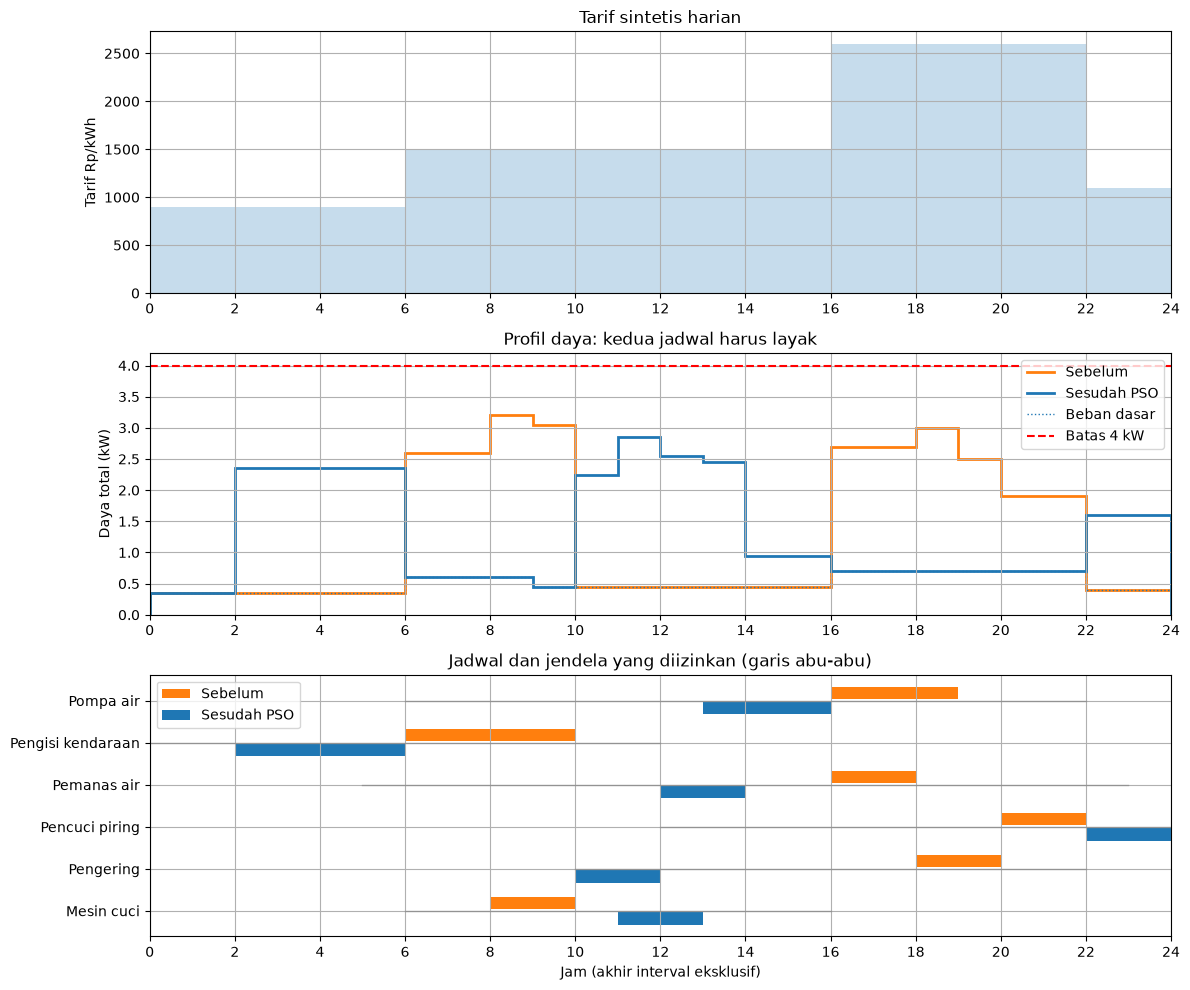

**Hasil rumah:** seed 101 biaya **Rp44,905/hari**, dari **Rp62,215/hari**. Hemat **Rp17,310 (27.82%)** dengan energi tetap 31.75 kWh. Puncak daya 2.85 kW memenuhi batas 4.0 kW. Kembali ke jadwal awal: False; 1 alat digeser dari jam yang diminta. Yang dicari biaya murah, sambil tetap menjaga batas daya.

In [10]:
home_check_configs = [BASE] if home_choice == 'baseline' else [BASE, CONFIG_MAP[home_choice]]
home_test_raw, home_test_summary, home_test_runs = run_experiment(
    home_objective, 2*M, decode_home, home_valid, home_check_configs, HOLDOUT_SEEDS, 'rumah_validasi')
save_runs(home_test_raw, home_test_summary, home_test_runs, 'rumah_validasi')
display(home_test_summary[['best', 'mean', 'std', 'feasible_rate', 'seconds_mean', 'evaluations']])
home_median_seed = int(home_test_raw[home_test_raw.config == home_choice].sort_values('cost').iloc[1].seed)
HOME_AFTER, selected_fallback, selected_repaired = decode_home(home_test_runs[(home_choice, home_median_seed)]['position'], details=True)
assert home_valid(HOME_BEFORE) and home_valid(HOME_AFTER)
assert np.isclose(home_profile(HOME_BEFORE).sum(), home_profile(HOME_AFTER).sum())
schedule = DEVICES.copy()
schedule['mulai_pso'] = HOME_AFTER
schedule['selesai_pso'] = HOME_AFTER + DURATION
schedule['biaya_awal_rp'] = [POWER[j]*TARIFF[s:s+DURATION[j]].sum() for j,s in enumerate(HOME_BEFORE)]
schedule['biaya_pso_rp'] = [POWER[j]*TARIFF[s:s+DURATION[j]].sum() for j,s in enumerate(HOME_AFTER)]
display(schedule)
base_cost = np.dot(BASE_LOAD, TARIFF)
home_comparison = pd.DataFrame([
    {'solusi': name, 'biaya_total_rp': home_cost_starts(s),
     'biaya_fleksibel_rp': home_cost_starts(s)-base_cost,
     'energi_kwh': home_profile(s).sum(), 'puncak_kw': home_profile(s).max(), 'layak': home_valid(s)}
    for name,s in [('Sebelum', HOME_BEFORE), ('Sesudah PSO', HOME_AFTER)]])
display(home_comparison)
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].stairs(TARIFF, np.arange(25), fill=True, alpha=0.25)
axes[0].set(ylabel='Tarif Rp/kWh', title='Tarif sintetis harian', xlim=(0,24))
for starts, label, color in [(HOME_BEFORE, 'Sebelum', 'tab:orange'), (HOME_AFTER, 'Sesudah PSO', 'tab:blue')]:
    axes[1].stairs(home_profile(starts), np.arange(25), label=label, color=color, linewidth=2)
axes[1].stairs(BASE_LOAD, np.arange(25), label='Beban dasar', linestyle=':')
axes[1].axhline(POWER_LIMIT, color='red', linestyle='--', label='Batas 4 kW')
axes[1].set(ylabel='Daya total (kW)', xlim=(0,24), title='Profil daya: kedua jadwal harus layak')
axes[1].legend()
for j in range(M):
    axes[2].barh(j+0.18, DURATION[j], left=HOME_BEFORE[j], height=0.3, color='tab:orange', label='Sebelum' if j==0 else None)
    axes[2].barh(j-0.18, DURATION[j], left=HOME_AFTER[j], height=0.3, color='tab:blue', label='Sesudah PSO' if j==0 else None)
    axes[2].plot([EARLIEST[j], DEADLINE[j]], [j,j], color='gray', lw=1, alpha=0.6)
axes[2].set(yticks=range(M), yticklabels=DEVICES.perangkat, xlabel='Jam (akhir interval eksklusif)', xlim=(0,24), title='Jadwal dan jendela yang diizinkan (garis abu-abu)')
axes[2].legend()
for ax in axes: ax.set_xticks(np.arange(0,25,2))
fig.tight_layout(); fig.savefig(OUTPUT/'rumah_jadwal_daya.png', dpi=150); plt.show()
home_saving = home_cost_starts(HOME_BEFORE)-home_cost_starts(HOME_AFTER)
display(Markdown(f'**Hasil rumah:** seed {home_median_seed}, biaya '
    f'**Rp{home_cost_starts(HOME_AFTER):,.0f}/hari**, dari **Rp{home_cost_starts(HOME_BEFORE):,.0f}/hari**. '
    f'Hemat **Rp{home_saving:,.0f} ({100*home_saving/home_cost_starts(HOME_BEFORE):.2f}%)** dengan energi tetap '
    f'{home_profile(HOME_AFTER).sum():.2f} kWh. Puncak daya {home_profile(HOME_AFTER).max():.2f} kW '
    f'memenuhi batas {POWER_LIMIT:.1f} kW. Kembali ke jadwal awal: {selected_fallback}; '
    f'{selected_repaired} alat digeser dari jam yang diminta. '
    'Yang dicari biaya murah, sambil tetap menjaga batas daya.'))
schedule.to_csv(OUTPUT/'rumah_jadwal.csv', index=False)
home_comparison.to_csv(OUTPUT/'rumah_sebelum_sesudah.csv', index=False)
pd.DataFrame({'jam': HOURS, 'sebelum_kw': home_profile(HOME_BEFORE), 'sesudah_kw': home_profile(HOME_AFTER), 'tarif_rp_kwh': TARIFF}).to_csv(OUTPUT/'rumah_profil_daya.csv', index=False)

Hematnya berasal dari pindah jam, bukan mengurangi lama pemakaian. Daya pada grafik sudah termasuk pemakaian dasar rumah.

## 5. Hasil akhirnya

Angka di bawah diambil langsung dari percobaan. Selisih negatif berarti pengaturan terpilih lebih baik dari pengaturan awal. Pengaturan tidak dipilih ulang setelah melihat tiga seed baru ini.

In [11]:
for label, raw, choice in [('kota', city_test_raw, city_choice), ('rumah', home_test_raw, home_choice)]:
    paired = raw.pivot(index='seed', columns='config', values='cost')
    paired['delta_terpilih_minus_baseline'] = paired[choice] - paired['baseline']
    display(Markdown(f'**Cek {label} dengan seed baru: `{choice}`.**'))
    display(paired)
    delta = paired['delta_terpilih_minus_baseline']
    verdict = 'lebih baik' if delta.mean() < -1e-9 else ('lebih buruk' if delta.mean() > 1e-9 else 'sama')
    display(Markdown(f'Pada seed baru, rata-ratanya **{verdict}** dari pengaturan awal; '
                     f'delta rata-rata = {delta.mean():.4f}, SD delta = {delta.std(ddof=1):.4f}. '
                     'Pengaturannya tidak dipilih ulang.'))

all_raw = pd.concat([city_raw, home_raw, city_test_raw, home_test_raw], ignore_index=True)
assert all_raw.feasible.all()
assert city_valid(CITY_AFTER) and home_valid(HOME_AFTER)
summary_final = {
    'city_selected_config': city_choice, 'home_selected_config': home_choice,
    'city_initial_km': city_cost_selected(CITY_BEFORE), 'city_final_km': city_cost_selected(CITY_AFTER),
    'city_reduction_percent': city_gain,
    'home_initial_rp': home_cost_starts(HOME_BEFORE), 'home_final_rp': home_cost_starts(HOME_AFTER),
    'home_saving_rp': home_saving, 'home_peak_kw': float(home_profile(HOME_AFTER).max()),
    'total_runs_tuning_and_holdout': len(all_raw), 'total_search_evaluations': int(all_raw.evals.sum()),
    'total_measured_pso_seconds': float(all_raw.seconds.sum()), 'all_final_solutions_feasible': bool(all_raw.feasible.all()),
    'tuning_seeds': SEEDS, 'holdout_seeds': HOLDOUT_SEEDS, 'data_seed': DATA_SEED,
}
(OUTPUT/'kesimpulan.json').write_text(json.dumps(summary_final, indent=2))
display(pd.Series(summary_final, name='Hasil aktual').to_frame())
display(Markdown(f'**Hasil latihan:** rata-rata jarak berubah dari '
    f'{summary_final["city_initial_km"]:.3f} menjadi {summary_final["city_final_km"]:.3f} km; '
    f'biaya rumah berubah dari Rp{summary_final["home_initial_rp"]:,.0f} menjadi Rp{summary_final["home_final_rp"]:,.0f}/hari. '
    f'Semua {len(all_raw)} hasil percobaan memenuhi aturan. '
    'Ini hasil latihan dengan data buatan, belum tentu jawaban paling bagus yang mungkin ada.'))

**Cek kota dengan seed baru: `c2_0.5`.**

config,baseline,c2_0.5,delta_terpilih_minus_baseline
seed,,,
101,1.401257,1.363516,-0.037741
202,1.272588,1.272588,0.000000
303,1.394674,1.363516,-0.031158


Pada seed baru, rata-ratanya **lebih baik** dari pengaturan awal; delta rata-rata = -0.0230, SD delta = 0.0202. Pengaturannya tidak dipilih ulang.

**Cek rumah dengan seed baru: `rounds_30`.**

config,baseline,rounds_30,delta_terpilih_minus_baseline
seed,,,
101,44905.0,44905.0,0.0
202,44005.0,44005.0,0.0
303,45865.0,45865.0,0.0


Pada seed baru, rata-ratanya **sama** dari pengaturan awal; delta rata-rata = 0.0000, SD delta = 0.0000. Pengaturannya tidak dipilih ulang.

,Hasil aktual
city_selected_config,c2_0.5
home_selected_config,rounds_30
city_initial_km,2.705271
city_final_km,1.363516
city_reduction_percent,49.597813
home_initial_rp,62215.0
home_final_rp,44905.0
home_saving_rp,17310.0
home_peak_kw,2.85
total_runs_tuning_and_holdout,152


**Hasil latihan:** rata-rata jarak berubah dari 2.705 menjadi 1.364 km; biaya rumah berubah dari Rp62,215 menjadi Rp44,905/hari. Semua 152 hasil percobaan memenuhi aturan. Ini hasil latihan dengan data buatan, belum tentu jawaban paling bagus yang mungkin ada.

Yang perlu diingat:

- PSO mencoba banyak jawaban, lalu menyimpan yang paling bagus.
- Tempat dan jadwal harus tetap memenuhi aturan.
- Lebih banyak mencoba belum tentu memberi hasil lebih baik.
- Ini baru data buatan, lima seed untuk memilih pengaturan, dan tiga untuk mengecek. Gabungan perubahan parameter belum diuji semua.
- Hasilnya **terbaik yang ditemukan**, belum terbukti paling baik dari semua kemungkinan.

Tabel, data, dan gambar ada di `hasil_pso`. Jumlah pemeriksaan pada ringkasan hanya untuk pencarian; uji awal dan pengecekan ulang tidak ikut dihitung. Waktu grafik dan penyimpanan file juga tidak masuk waktu PSO. Karena waktu komputer bisa berubah, pilihan pengaturan yang hasilnya hampir sama bisa berubah saat dijalankan ulang.